# Fase 1: Análise Exploratória (EDA)

In [10]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

df = pd.read_csv('G:\\Meu Drive\\ScTec\\Profissionalizar\\Curso Rápido de Machine Learning\\Projeto Final\\projeto-final-machine-learning\\data\\occupancy_completo\\occupancy_completo.csv')

### 1.1: Apresente as dimensões do dataset (número de linhas e colunas), os tipos de dados das variáveis (.info() / .dtypes) e o resumo estatístico descritivo das colunas numéricas via método .describe(). (Nota: Caso o arquivo possua coluna de data/hora como date, avalie seu formato ou descarte-a antes da modelagem numérica).

In [19]:
print (f"A quantidade de colunas é de: {df.shape[0]}")
print(f"A quantidade de linhas é de: {df.shape[1]}")

print(f"\nTipos de dados:\n{df.dtypes}")

print(f"\nResumo estatístico dos dados:\n{df.describe()}")

A quantidade de colunas é de: 20560
A quantidade de linhas é de: 7

Tipos de dados:
date                 str
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

Resumo estatístico dos dados:
        Temperature      Humidity         Light           CO2  HumidityRatio     Occupancy
count  20560.000000  20560.000000  20560.000000  20560.000000   20560.000000  20560.000000
mean      20.906212     27.655925    130.756622    690.553276       0.004228      0.231031
std        1.055315      4.982154    210.430875    311.201281       0.000768      0.421503
min       19.000000     16.745000      0.000000    412.750000       0.002674      0.000000
25%       20.200000     24.500000      0.000000    460.000000       0.003719      0.000000
50%       20.700000     27.290000      0.000000    565.416667       0.004292      0.000000
75%       21.525000     31.290000    301.000000    804.6666

### 1.2. Plote, no mínimo, 3 gráficos analíticos bem fundamentados utilizando bibliotecas como Matplotlib ou Seaborn (ex.: histogramas de distribuição das variáveis preditoras, gráfico de barras verificando a proporção das classes da variável alvo Occupancy e um mapa de calor com a correlação de Pearson entre as variáveis).

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns


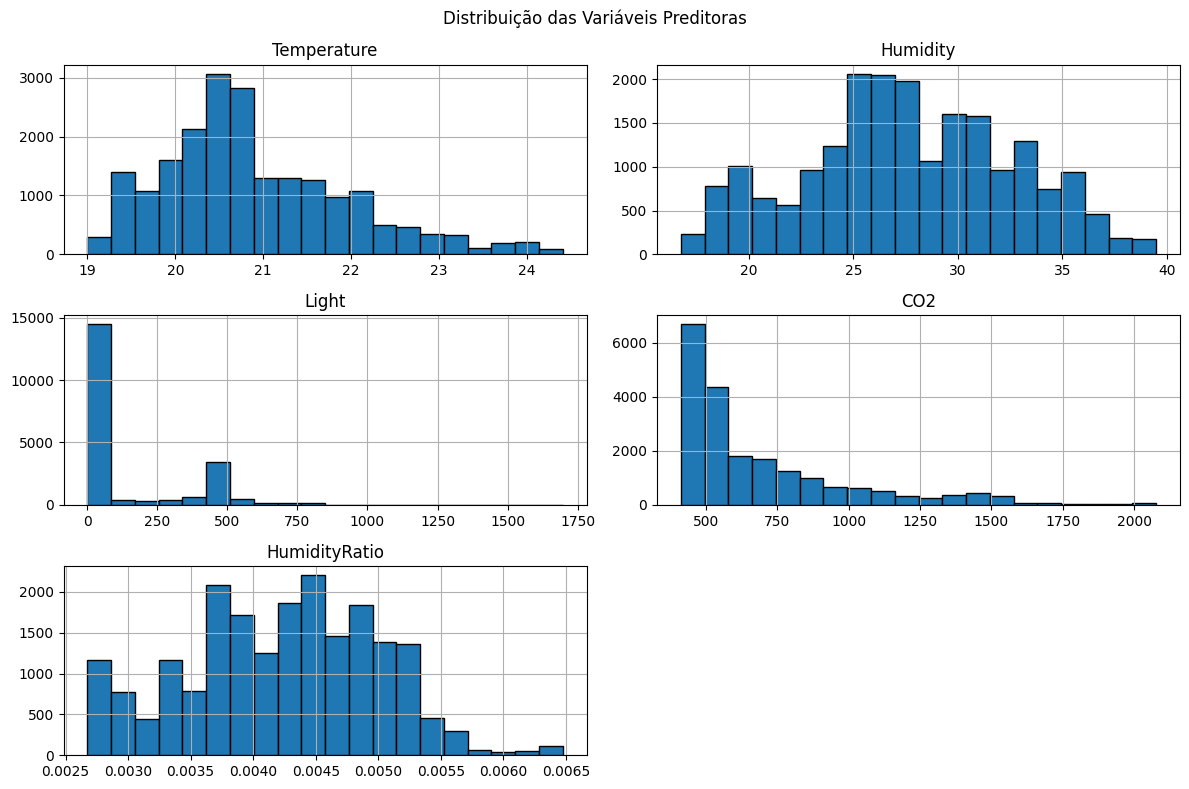

In [23]:
df.drop(columns=['Occupancy']).hist(bins=20, figsize=(12, 8), edgecolor='black')
plt.suptitle('Distribuição das Variáveis Preditoras')
plt.tight_layout()
plt.show()

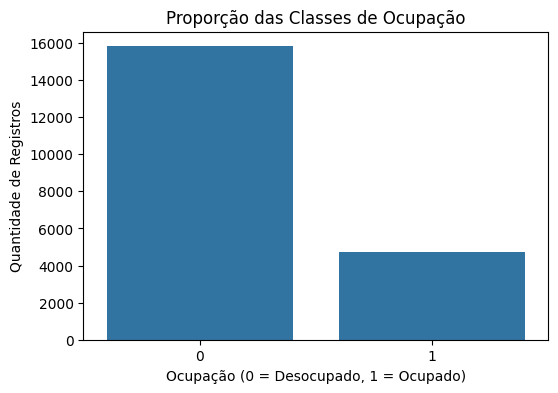

In [24]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Occupancy')
plt.title('Proporção das Classes de Ocupação')
plt.xlabel('Ocupação (0 = Desocupado, 1 = Ocupado)')
plt.ylabel('Quantidade de Registros')
plt.show()

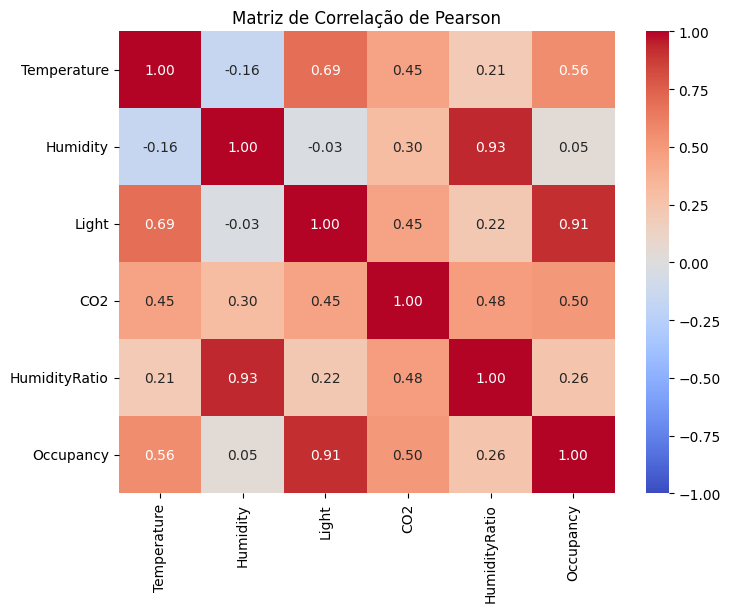

In [25]:
plt.figure(figsize=(8, 6))
correlacao = df.corr(numeric_only=True)
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Pearson')
plt.show()

### 1.3. Insira uma célula de texto analisando os valores numéricos e os padrões identificados nos gráficos (como a relação entre luminosidade, CO2 e ocupação), explicitando como eles direcionam a estratégia de modelagem.


Os gráficos de histograma apresentam uma forma assimétrica (ou seja, não têm forma de sino), mostrando diferenças temporais, que demosntram os momentos em que há pessoas ou não no ambiente. Por exemplo, o gráfico de 